# Peer Groups and Proxy Credit Spreads for Unquoted Emerging-Market Names (K-means & KNN)

Every emerging-market lender and CVA desk faces the same question: what credit spread should we use for a country or company that has no bond or CDS quote? The usual answer, an average over the same region and sector, puts Chile in the same bucket as Bolivia. This notebook builds peer groups from fundamentals instead and tests honestly whether they give better proxies.

**What it does.** It builds a peer-group engine from about 1,800 emerging-market USD bonds.

**K-means** clusters countries on macro and governance fundamentals, and issuers on their country risk and sector. **K-nearest neighbours (KNN)** then imputes a spread from the most similar quoted names.

Both are benchmarked against the regulatory-style region × sector bucket proxy, a ridge regression and LightGBM, in tests that hide each name before predicting it.

The engine then produces proxy sovereign spreads for countries with no USD bonds, a KNN spread-tier classifier, and the CVA impact of the choice of proxy.

**Data.** iShares J.P. Morgan USD EM sovereign (EMB) and EM corporate (CEMB) bond holdings, the U.S. Treasury par curve, and World Bank WDI (GDP per capita, growth, inflation, current account, reserves, external debt) and Worldwide Governance Indicators.

**Methods.** Z-spreads, a pooled maturity adjustment, K-means with silhouette selection, PCA for display, KNN regression and classification with tuned k and distance weighting, ridge and LightGBM benchmarks, and leave-one-country-out and grouped cross-validation by issuer.

**Key output.** The peer groups, the out-of-sample error of each proxy method for sovereigns and corporates, proxy spreads (with their nearest peers) for unquoted countries, spread-tier classification accuracy, and the CVA difference between bucket and KNN proxies.

## 1. The proxy-spread problem

Basel's CVA framework (and IFRS 13 fair value) requires a market-implied credit spread for every counterparty. When a name has no CDS, banks map it to a **proxy**: the average spread of a bucket of liquid names in the same **region, sector and rating**. Many EM counterparties of a development lender have no rating either, and region × sector buckets lump Chile together with Bolivia.

Two classic unsupervised and instance-based learners improve on this:
- **K-means** groups names into peer sets by their fundamentals instead of by geography. The proxy is the peer set's typical spread.
- **KNN** uses the $k$ most similar quoted names directly, weighting them by similarity. It also gives an audit trail: *which* names the proxy came from, which is exactly what a validator or auditor asks for.

The test is honest: each country (or issuer) is hidden, its spread is predicted from the others, and the error is measured in basis points.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
from scipy import optimize
from scipy.interpolate import PchipInterpolator
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV
from sklearn.metrics import (
    balanced_accuracy_score,
    confusion_matrix,
    silhouette_score,
)
from sklearn.model_selection import GroupKFold, LeaveOneOut
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 5
# EM USD sovereign/quasi-sovereign and EM corporate bonds
ISHARES_FUNDS = {"EMB": "239572", "CEMB": "239525"}
WB = "https://api.worldbank.org/v2"
WDI = {
    "NY.GDP.PCAP.CD": "gdp_pc",
    "NY.GDP.MKTP.KD.ZG": "growth",
    "FP.CPI.TOTL.ZG": "inflation",
    "BN.CAB.XOKA.GD.ZS": "current_account",
    "FI.RES.TOTL.MO": "reserves_months",
    "DT.DOD.DECT.GN.ZS": "ext_debt_gni",
}
WGI = {
    "GOV_WGI_GE.EST": "gov_effectiveness",
    "GOV_WGI_RL.EST": "rule_of_law",
    "GOV_WGI_PV.EST": "political_stability",
}
# 5y-equivalent spread tiers (bp)
TIERS = [0, 150, 350, 700, np.inf]
TIER_NAMES = ["<150", "150–350", "350–700", ">700"]
RECOVERY = 0.40

print(f"lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · run on 2026-10-20


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


def fetch_holdings(ticker):
    """
    One iShares fund's holdings file (all columns as text) with its as-of date.
    """
    url = f"https://www.ishares.com/us/products/{ISHARES_FUNDS[ticker]}/fund/latest-holdings.csv"
    lines = requests.get(
        url, headers=BROWSER_HEADERS, timeout=60
    ).text.splitlines()
    as_of = next(
        (
            l.split(",", 1)[1].strip('" ')
            for l in lines[:10]
            if "as of" in l.lower()
        ),
        "",
    )
    header = next(
        i for i, l in enumerate(lines) if l.startswith(("Ticker", "Name"))
    )
    t = pd.read_csv(
        io.StringIO("\n".join(lines[header:])), dtype=str, on_bad_lines="skip"
    )
    t["fund"], t["as_of"] = ticker, as_of
    return t


num = lambda s: pd.to_numeric(
    s.astype(str).str.replace(",", "", regex=False), errors="coerce"
)
raw = pd.concat(
    [
        cached(f"ishares_{t}", lambda t=t: fetch_holdings(t))
        for t in ISHARES_FUNDS
    ],
    ignore_index=True,
)
raw = raw[raw["Asset Class"] == "Fixed Income"]
AS_OF = pd.to_datetime(raw["as_of"].iloc[0], format="%b %d, %Y")

TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/daily-treasury-rates.csv/"
    "{y}/all?type=daily_treasury_yield_curve&field_tdr_date_value={y}&page&_format=csv"
)


def fetch_par():
    t = pd.read_csv(
        io.StringIO(
            requests.get(
                TREASURY_URL.format(y=AS_OF.year),
                headers=BROWSER_HEADERS,
                timeout=60,
            ).text
        )
    )
    t["date"] = pd.to_datetime(t["Date"], format="%m/%d/%Y")
    return t


par = cached("treasury_par", fetch_par).set_index("date").sort_index()
par = par.loc[:AS_OF].iloc[-1]
ten = {
    c: float(c.split()[0]) / (12 if "Mo" in c else 1)
    for c in par.index
    if re.match(r"^[\d.]+ (Mo|Yr)$", c)
}
pc = pd.Series({ten[c]: par[c] for c in ten}).dropna().sort_index() / 100
grid = np.arange(0.5, 30.01, 0.5)
par_g = PchipInterpolator(pc.index, pc.values)(grid)
dfs = []
# bootstrap semi-annual par bonds into discount factors
for c in par_g:
    dfs.append((1 - c / 2 * sum(dfs)) / (1 + c / 2))
zero_t = np.concatenate([[1 / 12], grid])
zero_r = np.concatenate(
    [[np.log(1 + pc.iloc[0] / 12) * 12], -np.log(np.array(dfs)) / grid]
)


def zero(t):
    return np.interp(
        np.asarray(t, float), zero_t, zero_r, left=zero_r[0], right=zero_r[-1]
    )


def DF(t):
    return np.exp(-zero(t) * np.asarray(t, float))


def schedule(maturity, coupon, settle=None):
    """
    Cash-flow times (years) and amounts per 100 face, and accrued interest, for
    a semi-annual fixed-rate bullet.
    """
    settle = AS_OF if settle is None else settle
    dates = [maturity]
    while dates[-1] > settle:
        dates.append(dates[-1] - pd.DateOffset(months=6))
    prev, cfd = dates[-1], sorted(dates[:-1])
    acc = coupon / 2 * (settle - prev).days / (cfd[0] - prev).days
    t = np.array([(d - settle).days / 365.25 for d in cfd])
    cf = np.full(len(t), coupon / 2)
    cf[-1] += 100
    return t, cf, acc


def zspread(maturity, coupon, clean):
    t, cf, acc = schedule(maturity, coupon)
    f = lambda s: np.sum(cf * np.exp(-(zero(t) + s) * t)) - (clean + acc)
    try:
        return optimize.brentq(f, -0.05, 0.9)
    except ValueError:
        return np.nan

## 3. Bonds, country fundamentals and the maturity adjustment

Every fixed-rate bond gets a z-spread over the Treasury zero curve. Bonds of the same issuer differ by maturity, so spreads are put on a common footing. A pooled regression $\log s_{ij}=a_i+b\log T_{ij}$ (one intercept per issuer, a common slope) gives each issuer a **5-year-equivalent spread** $e^{a_i+b\log 5}$. That is the quantity the proxies predict.

Country fundamentals come from the World Bank: the latest value in 2019–2025 of each indicator.
- GDP per capita (log), real growth, inflation (log), the current account and international reserves.
- External debt in % of GNI. It is not reported for high-income countries; missing values take the median and get a flag.
- Three Worldwide Governance Indicators: government effectiveness, rule of law and political stability.

In [3]:
SECTOR_MAP = {
    "Sovereign": "Sovereign",
    "Agency": "Quasi-sovereign",
    "Industrial": "Corporate",
    "Financial Institutions": "Financial",
    "Utility": "Utility",
    "Local Authority": "Quasi-sovereign",
}
b = pd.DataFrame({
    "issuer": (
        raw["Name"]
        .str.replace(r"\s+(RegS|144A|MTN|DISCO|PAR)$", "", regex=True)
        .str.strip()
    ),
    "fund": raw["fund"],
    "sector": raw["Sector"].map(SECTOR_MAP),
    "location": raw["Location"],
    "price": num(raw["Price"]),
    "coupon": num(raw["Coupon (%)"]),
    "par_held": num(raw["Par Value"]),
    "maturity": pd.to_datetime(
        raw["Maturity"], format="%b %d, %Y", errors="coerce"
    ),
    "isin": raw["ISIN"],
})
b = b.dropna(subset=["sector", "maturity", "price", "coupon"]).drop_duplicates(
    "isin"
)
b["T"] = (b["maturity"] - AS_OF).dt.days / 365.25
b = b[(b["T"] > 0.5) & (b["price"] > 10)]
b["z_bp"] = [
    zspread(m_, c_, p_) * 1e4
    for m_, c_, p_ in zip(b["maturity"], b["coupon"], b["price"])
]
b = b[b["z_bp"].between(5, 6000)].reset_index(drop=True)

# Pooled maturity slope with issuer fixed effects (within-issuer demeaning)
b["lz"], b["lT"] = np.log(b["z_bp"]), np.log(b["T"])
dm = b.groupby("issuer")[["lz", "lT"]].transform(lambda x: x - x.mean())
SLOPE = float((dm["lz"] * dm["lT"]).sum() / (dm["lT"] ** 2).sum())
b["l5"] = b["lz"] - SLOPE * (b["lT"] - np.log(5))
iss = (
    b.groupby("issuer")
    .agg(
        location=("location", "first"),
        sector=("sector", "first"),
        fund=("fund", "first"),
        l5=("l5", "median"),
        n_bonds=("isin", "size"),
        size=("par_held", "sum"),
    )
    .reset_index()
)
iss["s5"] = np.exp(iss["l5"])
print(
    f"{len(b):,} bonds of {len(iss):,} issuers in"
    f" {iss['location'].nunique()} locations, holdings as of"
    f" {AS_OF:%Y-%m-%d} · pooled maturity slope b = {SLOPE:.3f} (spreads rise"
    f" {(2 ** SLOPE - 1):.0%} per doubling of maturity)"
)
iss.groupby("sector")["s5"].describe(percentiles=[0.5])[
    ["count", "50%", "mean"]
].round(0)

1,722 bonds of 727 issuers in 75 locations, holdings as of 2026-10-19 · pooled maturity slope b = 0.206 (spreads rise 15% per doubling of maturity)


,count,50%,mean
sector,,,
Corporate,255.00,157.00,255.00
Financial,187.00,110.00,193.00
Quasi-sovereign,152.00,91.00,105.00
Sovereign,88.00,131.00,249.00
Utility,45.00,181.00,299.00


In [4]:
def wb_json(url):
    out, page = [], 1
    while True:
        j = requests.get(f"{url}&page={page}", timeout=90).json()
        out += j[1] or []
        if page >= j[0]["pages"]:
            return out
        page += 1


def fetch_macro():
    countries = pd.DataFrame([
        {
            "iso3": c["id"],
            "wb_name": c["name"],
            "region": c["region"]["value"],
            "income": c["incomeLevel"]["value"],
        }
        for c in wb_json(f"{WB}/country?format=json&per_page=400")
        if c["region"]["value"] != "Aggregates"
    ])
    rows = []
    for ind, name in {**WDI, **WGI}.items():
        src = 3 if ind in WGI else 2
        for o in wb_json(
            f"{WB}/country/all/indicator/{ind}?source={src}&format=json&per_page=20000&date=2019:2025"
        ):
            if o["value"] is not None:
                rows.append({
                    "wb_name": o["country"]["value"],
                    "iso3": o.get("countryiso3code") or None,
                    "var": name,
                    "year": int(o["date"]),
                    "value": o["value"],
                })
    obs = pd.DataFrame(rows)
    obs["iso3"] = obs["iso3"].fillna(
        obs["wb_name"].map(countries.set_index("wb_name")["iso3"])
    )
    latest = (
        obs.dropna(subset=["iso3"])
        .sort_values("year")
        .groupby(["iso3", "var"])["value"]
        .last()
        .unstack()
    )
    return countries.merge(latest.reset_index(), on="iso3", how="left")


macro = cached("wb_macro", fetch_macro, max_age_hours=24 * 30)
NAME_FIX = {
    "Korea (South)": "Korea, Rep.",
    "Turkey": "Turkiye",
    "Egypt": "Egypt, Arab Rep.",
    "Cote D'Ivoire (Ivory Coast)": "Cote d'Ivoire",
    "Democratic Rep of Congo": "Congo, Dem. Rep.",
    "Hong Kong": "Hong Kong SAR, China",
    "Macau": "Macao SAR, China",
    "Czech Republic": "Czechia",
    "Slovakia": "Slovak Republic",
    "Russia": "Russian Federation",
    "Venezuela": "Venezuela, RB",
    "Lao": "Lao PDR",
    "Kyrgyzstan": "Kyrgyz Republic",
    "Gambia": "Gambia, The",
    "Bahamas": "Bahamas, The",
}
iss["wb_name"] = iss["location"].replace(NAME_FIX)
MV = list(WDI.values()) + list(WGI.values())
macro["log_gdp_pc"] = np.log(macro["gdp_pc"])
macro["log_infl"] = np.log1p(macro["inflation"].clip(-5, 300) / 100)
macro["ext_debt_missing"] = macro["ext_debt_gni"].isna().astype(int)
macro["ext_debt_gni"] = (
    macro["ext_debt_gni"].fillna(macro["ext_debt_gni"].median()).clip(0, 250)
)
FX = [
    "log_gdp_pc",
    "growth",
    "log_infl",
    "current_account",
    "reserves_months",
    "ext_debt_gni",
    "ext_debt_missing",
    "gov_effectiveness",
    "rule_of_law",
    "political_stability",
]
iss = iss.merge(
    macro[["wb_name", "iso3", "region", "income"] + FX],
    on="wb_name",
    how="left",
)
no_macro = sorted(iss.loc[iss["iso3"].isna(), "location"].unique())
iss = iss.dropna(subset=["iso3"]).reset_index(drop=True)
# a few gaps (e.g. reserves) take the cross-country median
for c in FX:
    iss[c] = iss[c].fillna(macro[c].median())
print(
    f"Macro matched for {iss['iso3'].nunique()} countries; dropped locations"
    f" without World Bank data: {', '.join(no_macro)}"
)

Macro matched for 74 countries; dropped locations without World Bank data: Taiwan


## 4. Sovereigns: K-means peer groups and KNN proxies

**Universe.** One observation per country with sovereign bonds: its 5-year-equivalent sovereign spread and ten fundamentals (standardised).

**K-means.** The number of clusters is chosen by the silhouette score over $K=3\ldots10$. The proxy for a hidden country is the median spread of the *other* members of its cluster, with the clustering re-fitted without it.

**KNN.** The proxy is the distance-weighted average of the log spreads of the $k$ nearest countries; $k$ is chosen by an inner leave-one-out search.

**KNN with a learned metric.** Plain KNN treats every standardised feature as equally important. A light form of *metric learning* first fits a ridge regression on the training countries and stretches each feature by the size of its coefficient. Neighbours are then similar in the dimensions that matter for spreads.

**Benchmarks.**
- region median: the regulatory-style bucket;
- a ridge regression on the same fundamentals;
- LightGBM, small and regularised.

All are scored by **leave-one-country-out**: the country is removed before scaling, clustering and fitting.

In [5]:
sov = (
    iss[iss["sector"] == "Sovereign"]
    .groupby("iso3")
    .agg(
        country=("location", "first"),
        region=("region", "first"),
        income=("income", "first"),
        l5=("l5", "median"),
        **{c: (c, "first") for c in FX},
    )
    .reset_index()
)
Xs, ys = sov[FX].to_numpy(float), sov["l5"].to_numpy()
sc_all = StandardScaler().fit(Xs)
Z = sc_all.transform(Xs)
sil = {
    k: silhouette_score(
        Z, KMeans(k, n_init=20, random_state=SEED).fit_predict(Z)
    )
    for k in range(3, 11)
}
K_SOV = max(sil, key=sil.get)
km_sov = KMeans(K_SOV, n_init=20, random_state=SEED).fit(Z)
sov["cluster"] = km_sov.labels_


def best_k(Xtr, ytr, ks=range(3, 12)):
    errs = {}
    for k in ks:
        if k >= len(ytr) - 1:
            break
        p = [
            KNeighborsRegressor(k, weights="distance")
            .fit(np.delete(Xtr, i, 0), np.delete(ytr, i))
            .predict(Xtr[i : i + 1])[0]
            for i in range(len(ytr))
        ]
        errs[k] = np.median(np.abs(np.exp(p) - np.exp(ytr)))
    return min(errs, key=errs.get), errs


def ridge_weights(Ztr, ytr):
    """
    Supervised metric for KNN: scale each standardised feature by its |ridge
    coefficient| (mean weight 1).
    """
    w = np.abs(RidgeCV(alphas=np.logspace(-2, 3, 20)).fit(Ztr, ytr).coef_)
    return w / w.mean() if w.sum() > 0 else np.ones_like(w)


pred = {
    m_: np.zeros(len(sov))
    for m_ in [
        "region median",
        "K-means cluster median",
        "KNN",
        "KNN, ridge-weighted metric",
        "ridge",
        "LightGBM",
    ]
}
k_used = []
for i in range(len(sov)):
    tr = np.arange(len(sov)) != i
    sc = StandardScaler().fit(Xs[tr])
    Ztr, Zte = sc.transform(Xs[tr]), sc.transform(Xs[i : i + 1])
    reg = sov.loc[tr, "region"] == sov.at[i, "region"]
    pred["region median"][i] = (
        np.median(ys[tr][reg]) if reg.sum() else np.median(ys[tr])
    )
    km = KMeans(K_SOV, n_init=10, random_state=SEED).fit(Ztr)
    c = km.predict(Zte)[0]
    pred["K-means cluster median"][i] = np.median(ys[tr][km.labels_ == c])
    k, _ = best_k(Ztr, ys[tr])
    k_used.append(k)
    pred["KNN"][i] = (
        KNeighborsRegressor(k, weights="distance")
        .fit(Ztr, ys[tr])
        .predict(Zte)[0]
    )
    w_ = ridge_weights(Ztr, ys[tr])
    kw, _ = best_k(Ztr * w_, ys[tr])
    pred["KNN, ridge-weighted metric"][i] = (
        KNeighborsRegressor(kw, weights="distance")
        .fit(Ztr * w_, ys[tr])
        .predict(Zte * w_)[0]
    )
    pred["ridge"][i] = (
        RidgeCV(alphas=np.logspace(-2, 3, 20)).fit(Ztr, ys[tr]).predict(Zte)[0]
    )
    pred["LightGBM"][i] = (
        lgb.LGBMRegressor(
            n_estimators=200,
            learning_rate=0.05,
            num_leaves=7,
            min_child_samples=5,
            reg_lambda=1.0,
            verbose=-1,
            random_state=SEED,
        )
        .fit(Ztr, ys[tr])
        .predict(Zte)[0]
    )
sov_score = pd.DataFrame({
    m_: {
        "median abs error (bp)": np.median(np.abs(np.exp(p) - np.exp(ys))),
        "mean abs error (bp)": np.mean(np.abs(np.exp(p) - np.exp(ys))),
        "median abs log error": np.median(np.abs(p - ys)),
        "rank correlation": pd.Series(p).corr(
            pd.Series(ys), method="spearman"
        ),
    }
    for m_, p in pred.items()
}).T
sov_score = sov_score.sort_values("median abs error (bp)")
for m_, p in pred.items():
    sov[f"proxy_{m_}"] = np.exp(p)
sov["s5"] = np.exp(sov["l5"])
print(
    f"{len(sov)} sovereigns · silhouette picks K = {K_SOV} (score"
    f" {sil[K_SOV]:.2f}) · KNN inner-LOO k: median"
    f" {int(np.median(k_used))} (range {min(k_used)}–{max(k_used)})"
)
sov_score.round(3)

47 sovereigns · silhouette picks K = 5 (score 0.37) · KNN inner-LOO k: median 6 (range 3–11)


,median abs error (bp),mean abs error (bp),median abs log error,rank correlation
ridge,37.53,113.79,0.32,0.76
LightGBM,40.25,145.79,0.36,0.60
KNN,46.77,142.85,0.40,0.61
"KNN, ridge-weighted metric",49.77,145.99,0.43,0.68
K-means cluster median,54.15,193.88,0.49,0.51
region median,56.80,160.39,0.45,0.28


In [6]:
prof = (
    sov.groupby("cluster")
    .agg(
        countries=(
            "country",
            lambda s: ", ".join(sorted(s)[:8]) + (" …" if len(s) > 8 else ""),
        ),
        n=("country", "size"),
        median_spread_bp=("s5", "median"),
        gdp_pc=("log_gdp_pc", lambda x: np.exp(x).median()),
        gov_eff=("gov_effectiveness", "median"),
        ext_debt=("ext_debt_gni", "median"),
    )
    .sort_values("median_spread_bp")
)
prof.round(1)

,countries,n,median_spread_bp,gdp_pc,gov_eff,ext_debt
cluster,,,,,,
0,"Bahrain, Chile, Costa Rica, Hungary, Latvia, O...",12,82.60,"23,876.90",0.40,43.20
2,"Angola, Azerbaijan, Benin, Bolivia, Brazil, Bu...",31,157.60,"5,865.90",-0.10,46.90
3,Argentina,1,165.20,"14,898.10",0.30,39.10
1,"Senegal, Suriname",2,783.40,"4,512.30",0.10,139.90
4,Lebanon,1,"2,627.30","4,473.30",-1.10,250.00


## 5. Corporates and quasi-sovereigns: issuer-level proxies

**Proxy target.** For a company with no quote, the proxy is the 5-year-equivalent spread of each quasi-sovereign, corporate, financial and utility issuer.

**Features**, observable for any counterparty:
- its **country's sovereign spread**, which for countries without sovereign bonds is the KNN sovereign proxy from §4: the "sovereign ceiling" channel;
- the country's fundamentals;
- the sector;
- the size of its bond debt (log par held by the two funds), as a proxy for issuer size.

Coupons and prices are excluded: an unquoted counterparty has neither.

**Proxies compared, by 5-fold cross-validation grouped by issuer:**
- country × sector median, falling back to region × sector;
- region × sector median: the Basel-style bucket;
- the issuer's own sovereign spread;
- K-means peer group (clusters chosen by silhouette);
- KNN, plain (the sovereign spread counts three times as much as any other feature) and with the ridge-learned metric;
- LightGBM.

In [7]:
sov_level = sov.set_index("iso3")["l5"]
# Countries with corporates but no sovereign bonds in EMB get a KNN sovereign
# proxy fitted on all sovereigns
W_SOV = ridge_weights(Z, ys)
k_all, _ = best_k(Z * W_SOV, ys)
knn_sov_all = KNeighborsRegressor(k_all, weights="distance").fit(Z * W_SOV, ys)
need = macro[
    macro["iso3"].isin(iss["iso3"]) & ~macro["iso3"].isin(sov_level.index)
].copy()
for c in FX:
    need[c] = need[c].fillna(macro[c].median())
sov_proxy_fill = pd.Series(
    knn_sov_all.predict(sc_all.transform(need[FX].to_numpy(float)) * W_SOV),
    index=need["iso3"],
)
corp = iss[iss["sector"] != "Sovereign"].copy()
corp["sov_l5"] = (
    corp["iso3"].map(sov_level).fillna(corp["iso3"].map(sov_proxy_fill))
)
corp["sov_quoted"] = corp["iso3"].isin(sov_level.index).astype(int)
corp["log_size"] = np.log(corp["size"].clip(lower=1e5))
for s_ in ["Quasi-sovereign", "Corporate", "Financial", "Utility"]:
    corp[f"is_{s_}"] = (corp["sector"] == s_).astype(int)
CF = (
    ["sov_l5", "sov_quoted", "log_size"]
    + [
        f"is_{s_}"
        for s_ in ["Quasi-sovereign", "Corporate", "Financial", "Utility"]
    ]
    + FX
)
corp = corp.dropna(subset=CF).reset_index(drop=True)
Xc, yc = corp[CF].to_numpy(float), corp["l5"].to_numpy()
# KNN distance: the sovereign spread counts three times as much as any single
# feature
W = np.ones(len(CF))
W[0] = 3.0
cpred = {
    m_: np.zeros(len(corp))
    for m_ in [
        "country × sector median",
        "region × sector median (Basel-style)",
        "own sovereign spread",
        "K-means peer group",
        "KNN",
        "KNN, ridge-weighted metric",
        "LightGBM",
    ]
}
gk = GroupKFold(5)
silc, kc_used = [], []
for tr, te in gk.split(Xc, groups=corp["issuer"]):
    ctr, cte = corp.iloc[tr], corp.iloc[te]
    med_cs = ctr.groupby(["iso3", "sector"])["l5"].median()
    med_rs = ctr.groupby(["region", "sector"])["l5"].median()
    cpred["region × sector median (Basel-style)"][te] = [
        med_rs.get((r_, s_), ctr["l5"].median())
        for r_, s_ in zip(cte["region"], cte["sector"])
    ]
    cpred["country × sector median"][te] = [
        med_cs.get((c_, s_), med_rs.get((r_, s_), ctr["l5"].median()))
        for c_, s_, r_ in zip(cte["iso3"], cte["sector"], cte["region"])
    ]
    # typical corporate-over-sovereign premium
    gap = (ctr["l5"] - ctr["sov_l5"]).median()
    cpred["own sovereign spread"][te] = cte["sov_l5"] + gap
    sc = StandardScaler().fit(Xc[tr])
    Ztr, Zte = sc.transform(Xc[tr]) * W, sc.transform(Xc[te]) * W
    sk = {
        k: silhouette_score(
            Ztr,
            KMeans(k, n_init=10, random_state=SEED).fit_predict(Ztr),
            sample_size=min(2000, len(tr)),
            random_state=SEED,
        )
        for k in range(4, 31, 2)
    }
    kk = max(sk, key=sk.get)
    silc.append(kk)
    km = KMeans(kk, n_init=10, random_state=SEED).fit(Ztr)
    cm = pd.Series(yc[tr]).groupby(km.labels_).median()
    cpred["K-means peer group"][te] = cm.reindex(km.predict(Zte)).to_numpy()
    errs = {}
    inner = GroupKFold(4)
    for k in [3, 5, 8, 12, 20, 30]:
        e_ = []
        for itr, ite in inner.split(Ztr, groups=ctr["issuer"]):
            e_.append(
                np.abs(
                    KNeighborsRegressor(k, weights="distance")
                    .fit(Ztr[itr], yc[tr][itr])
                    .predict(Ztr[ite])
                    - yc[tr][ite]
                )
            )
        errs[k] = np.median(np.concatenate(e_))
    kb = min(errs, key=errs.get)
    kc_used.append(kb)
    cpred["KNN"][te] = (
        KNeighborsRegressor(kb, weights="distance")
        .fit(Ztr, yc[tr])
        .predict(Zte)
    )
    Ztr0, Zte0 = sc.transform(Xc[tr]), sc.transform(Xc[te])
    w_ = ridge_weights(Ztr0, yc[tr])
    errs = {}
    for k in [3, 5, 8, 12, 20, 30]:
        e_ = []
        for itr, ite in inner.split(Ztr0, groups=ctr["issuer"]):
            e_.append(
                np.abs(
                    KNeighborsRegressor(k, weights="distance")
                    .fit(Ztr0[itr] * w_, yc[tr][itr])
                    .predict(Ztr0[ite] * w_)
                    - yc[tr][ite]
                )
            )
        errs[k] = np.median(np.concatenate(e_))
    kw = min(errs, key=errs.get)
    cpred["KNN, ridge-weighted metric"][te] = (
        KNeighborsRegressor(kw, weights="distance")
        .fit(Ztr0 * w_, yc[tr])
        .predict(Zte0 * w_)
    )
    cpred["LightGBM"][te] = (
        lgb.LGBMRegressor(
            n_estimators=500,
            learning_rate=0.03,
            num_leaves=15,
            min_child_samples=15,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            verbose=-1,
            random_state=SEED,
        )
        .fit(Xc[tr], yc[tr])
        .predict(Xc[te])
    )
corp_score = pd.DataFrame({
    m_: {
        "median abs error (bp)": np.median(np.abs(np.exp(p) - np.exp(yc))),
        "mean abs error (bp)": np.mean(np.abs(np.exp(p) - np.exp(yc))),
        "median abs log error": np.median(np.abs(p - yc)),
        "rank correlation": pd.Series(p).corr(
            pd.Series(yc), method="spearman"
        ),
    }
    for m_, p in cpred.items()
}).T
corp_score = corp_score.sort_values("median abs error (bp)")
print(
    f"{len(corp)} non-sovereign issuers in {corp['iso3'].nunique()} countries"
    f" ({(1 - corp['sov_quoted'].mean()):.0%} in countries without quoted"
    f" sovereign bonds) · K-means K chosen per fold: {silc} · KNN k per fold:"
    f" {kc_used}"
)
corp_score.round(3)

633 non-sovereign issuers in 56 countries (46% in countries without quoted sovereign bonds) · K-means K chosen per fold: [28, 30, 28, 30, 30] · KNN k per fold: [30, 8, 5, 30, 8]


,median abs error (bp),mean abs error (bp),median abs log error,rank correlation
country × sector median,34.76,101.72,0.30,0.70
"KNN, ridge-weighted metric",37.55,109.16,0.35,0.66
KNN,38.30,110.79,0.36,0.66
LightGBM,38.66,106.20,0.34,0.68
region × sector median (Basel-style),39.60,112.52,0.38,0.55
K-means peer group,41.30,110.90,0.36,0.59
own sovereign spread,43.06,115.71,0.39,0.45


## 6. KNN as a classifier: spread tiers

Risk appetite frameworks often work with tiers rather than exact spreads. A KNN classifier assigns each hidden issuer to one of four 5-year spread tiers: < 150 bp (investment-grade-like), 150–350, 350–700, > 700 bp (distressed). It is scored by balanced accuracy, with grouped cross-validation, against the bucket proxy's implied tier.

In [8]:
tier = lambda l: np.digitize(np.exp(l), TIERS[1:-1])
yt = tier(yc)
tpred_knn, tpred_bucket = np.zeros(len(corp), int), tier(
    cpred["region × sector median (Basel-style)"]
)
for tr, te in gk.split(Xc, groups=corp["issuer"]):
    sc = StandardScaler().fit(Xc[tr])
    clf = KNeighborsClassifier(15, weights="distance").fit(
        sc.transform(Xc[tr]) * W, yt[tr]
    )
    tpred_knn[te] = clf.predict(sc.transform(Xc[te]) * W)
tier_score = pd.Series(
    {
        "KNN classifier": balanced_accuracy_score(yt, tpred_knn),
        "KNN regression → tier": balanced_accuracy_score(
            yt, tier(cpred["KNN"])
        ),
        "region × sector bucket → tier": balanced_accuracy_score(
            yt, tpred_bucket
        ),
        "always the most common tier": balanced_accuracy_score(
            yt, np.full(len(yt), np.bincount(yt).argmax())
        ),
    },
    name="balanced accuracy",
)
cmat = pd.DataFrame(
    confusion_matrix(yt, tpred_knn),
    index=[f"true {t}" for t in TIER_NAMES],
    columns=[f"pred {t}" for t in TIER_NAMES],
)
display(tier_score.round(3).to_frame())
cmat

,balanced accuracy
KNN classifier,0.40
KNN regression → tier,0.42
region × sector bucket → tier,0.40
always the most common tier,0.25


,pred <150,pred 150–350,pred 350–700,pred >700
true <150,342,52,4,0
true 150–350,69,85,13,2
true 350–700,21,19,6,3
true >700,5,6,4,2


## 7. Applications: unquoted sovereigns and the CVA impact of the proxy choice

**Proxies for countries with no USD bonds in the index.** The KNN sovereign model (fitted on all quoted sovereigns) produces a proxy spread for every low- and middle-income country in the World Bank data that has complete fundamentals but no EMB bonds. Each comes with its three nearest quoted peers (the audit trail) and its K-means peer group.

**CVA impact.** For a 5-year USD interest-rate swap with a stylised expected-exposure profile $EE(t)=0.6\%\cdot\sqrt{t}\cdot N$ on $N=\$100$mm, the unilateral CVA is $(1-R)\sum_i EE(t_i)D(t_i)[Q(t_{i-1})-Q(t_i)]$ with a flat hazard $\lambda=s/(1-R)$. It is computed with each issuer's actual spread, the KNN proxy and the bucket proxy, on the hidden-issuer predictions from §5.

In [9]:
cand = macro[
    ~macro["iso3"].isin(sov_level.index)
    & macro["income"].isin(
        ["Low income", "Lower middle income", "Upper middle income"]
    )
].copy()
cand = cand.dropna(
    subset=["gdp_pc", "inflation", "current_account", "gov_effectiveness"]
)
for c in FX:
    cand[c] = cand[c].fillna(macro[c].median())
Zc = sc_all.transform(cand[FX].to_numpy(float))
cand["proxy_bp"] = np.exp(knn_sov_all.predict(Zc * W_SOV))
dist, idx = knn_sov_all.kneighbors(Zc * W_SOV, n_neighbors=3)
cand["nearest quoted peers"] = [
    ", ".join(sov["country"].iloc[j].tolist()) for j in idx
]
cand["K-means peer group"] = km_sov.predict(Zc)
cand["region median bp"] = cand["region"].map(
    sov.groupby("region")["s5"].median()
)
unq = cand.sort_values("proxy_bp")[[
    "wb_name",
    "region",
    "income",
    "proxy_bp",
    "region median bp",
    "nearest quoted peers",
    "K-means peer group",
]]
print(
    "Learned feature weights (sovereign KNN):",
    ", ".join(
        f"{c} {w:.2f}" for c, w in sorted(zip(FX, W_SOV), key=lambda x: -x[1])
    ),
)
print(
    f"KNN (ridge-weighted metric, k = {k_all}) sovereign proxies for"
    f" {len(unq)} unquoted low- and middle-income countries"
)
display(unq.head(8).round(0))
unq.tail(8).round(0)

Learned feature weights (sovereign KNN): ext_debt_gni 2.78, reserves_months 1.16, political_stability 1.11, log_gdp_pc 1.01, ext_debt_missing 0.95, rule_of_law 0.88, gov_effectiveness 0.75, log_infl 0.54, growth 0.52, current_account 0.29
KNN (ridge-weighted metric, k = 3) sovereign proxies for 79 unquoted low- and middle-income countries


,wb_name,region,income,proxy_bp,region median bp,nearest quoted peers,K-means peer group
193,Timor-Leste,East Asia & Pacific,Lower middle income,61.00,76.00,"Azerbaijan, Guatemala, Philippines",1
138,Malaysia,East Asia & Pacific,Upper middle income,66.00,76.00,"Chile, Oman, Poland",0
204,Uzbekistan,Europe & Central Asia,Lower middle income,71.00,81.00,"Peru, Kazakhstan, Paraguay",2
209,Viet Nam,East Asia & Pacific,Upper middle income,72.00,76.00,"Ghana, Indonesia, Azerbaijan",2
211,Samoa,East Asia & Pacific,Upper middle income,74.00,76.00,"Uruguay, Bulgaria, Peru",0
30,Botswana,Sub-Saharan Africa,Upper middle income,77.00,221.00,"Azerbaijan, Dominican Republic, Brazil",0
89,India,South Asia,Lower middle income,82.00,165.00,"Philippines, Indonesia, Morocco",2
92,Iraq,"Middle East, North Africa, Afghanistan & Pakistan",Upper middle income,85.00,252.00,"Guatemala, Peru, Philippines",2


,wb_name,region,income,proxy_bp,region median bp,nearest quoted peers,K-means peer group
72,Guinea,Sub-Saharan Africa,Lower middle income,343.00,221.00,"Kenya, Egypt, Pakistan",2
40,"Congo, Rep.",Sub-Saharan Africa,Lower middle income,360.00,221.00,"Bolivia, Ecuador, Cote D'Ivoire (Ivory Coast)",2
136,Mauritius,Sub-Saharan Africa,Upper middle income,374.00,221.00,"Suriname, Jordan, Senegal",0
216,Zimbabwe,Sub-Saharan Africa,Lower middle income,388.00,221.00,"Bolivia, Egypt, Pakistan",2
183,Eswatini,Sub-Saharan Africa,Lower middle income,404.00,221.00,"Bolivia, Egypt, Kenya",2
215,Zambia,Sub-Saharan Africa,Lower middle income,541.00,221.00,"Ukraine, Suriname, Senegal",2
132,Mongolia,East Asia & Pacific,Upper middle income,617.00,76.00,"Senegal, Suriname, Ukraine",1
134,Mozambique,Sub-Saharan Africa,Low income,"1,241.00",221.00,"Lebanon, Senegal, Suriname",4


In [10]:
def cva(spread_bp, N=100e6, T=5.0):
    t = np.arange(0.25, T + 1e-9, 0.25)
    lam = spread_bp / 1e4 / (1 - RECOVERY)
    Q = np.exp(-lam * np.concatenate([[0], t]))
    EE = 0.006 * np.sqrt(t) * N
    return (1 - RECOVERY) * np.sum(EE * DF(t) * (Q[:-1] - Q[1:]))


corp["s5_knn"], corp["s5_bucket"] = np.exp(
    cpred["KNN, ridge-weighted metric"]
), np.exp(cpred["region × sector median (Basel-style)"])
corp["cva_true"] = corp["s5"].map(cva)
corp["cva_knn"], corp["cva_bucket"] = corp["s5_knn"].map(cva), corp[
    "s5_bucket"
].map(cva)
cva_tab = pd.DataFrame(
    {
        "KNN proxy": [
            np.median(np.abs(corp["cva_knn"] - corp["cva_true"])),
            np.mean(np.abs(corp["cva_knn"] - corp["cva_true"])),
            (corp["cva_knn"] - corp["cva_true"]).sum()
            / corp["cva_true"].sum(),
        ],
        "region × sector bucket": [
            np.median(np.abs(corp["cva_bucket"] - corp["cva_true"])),
            np.mean(np.abs(corp["cva_bucket"] - corp["cva_true"])),
            (corp["cva_bucket"] - corp["cva_true"]).sum()
            / corp["cva_true"].sum(),
        ],
    },
    index=[
        "median abs CVA error per counterparty ($)",
        "mean abs CVA error per counterparty ($)",
        "portfolio CVA bias (share)",
    ],
)
print(
    f"Median CVA with actual spreads: ${corp['cva_true'].median():,.0f} per"
    f" $100mm swap · portfolio of {len(corp)} counterparties:"
    f" ${corp['cva_true'].sum() / 1e6:,.1f}mm"
)
cva_tab.round(3)

Median CVA with actual spreads: $43,371 per $100mm swap · portfolio of 633 counterparties: $39.6mm


,KNN proxy,region × sector bucket
median abs CVA error per counterparty ($),"13,291.56","14,342.67"
mean abs CVA error per counterparty ($),"25,967.70","27,759.29"
portfolio CVA bias (share),-0.07,-0.19


## 8. Charts

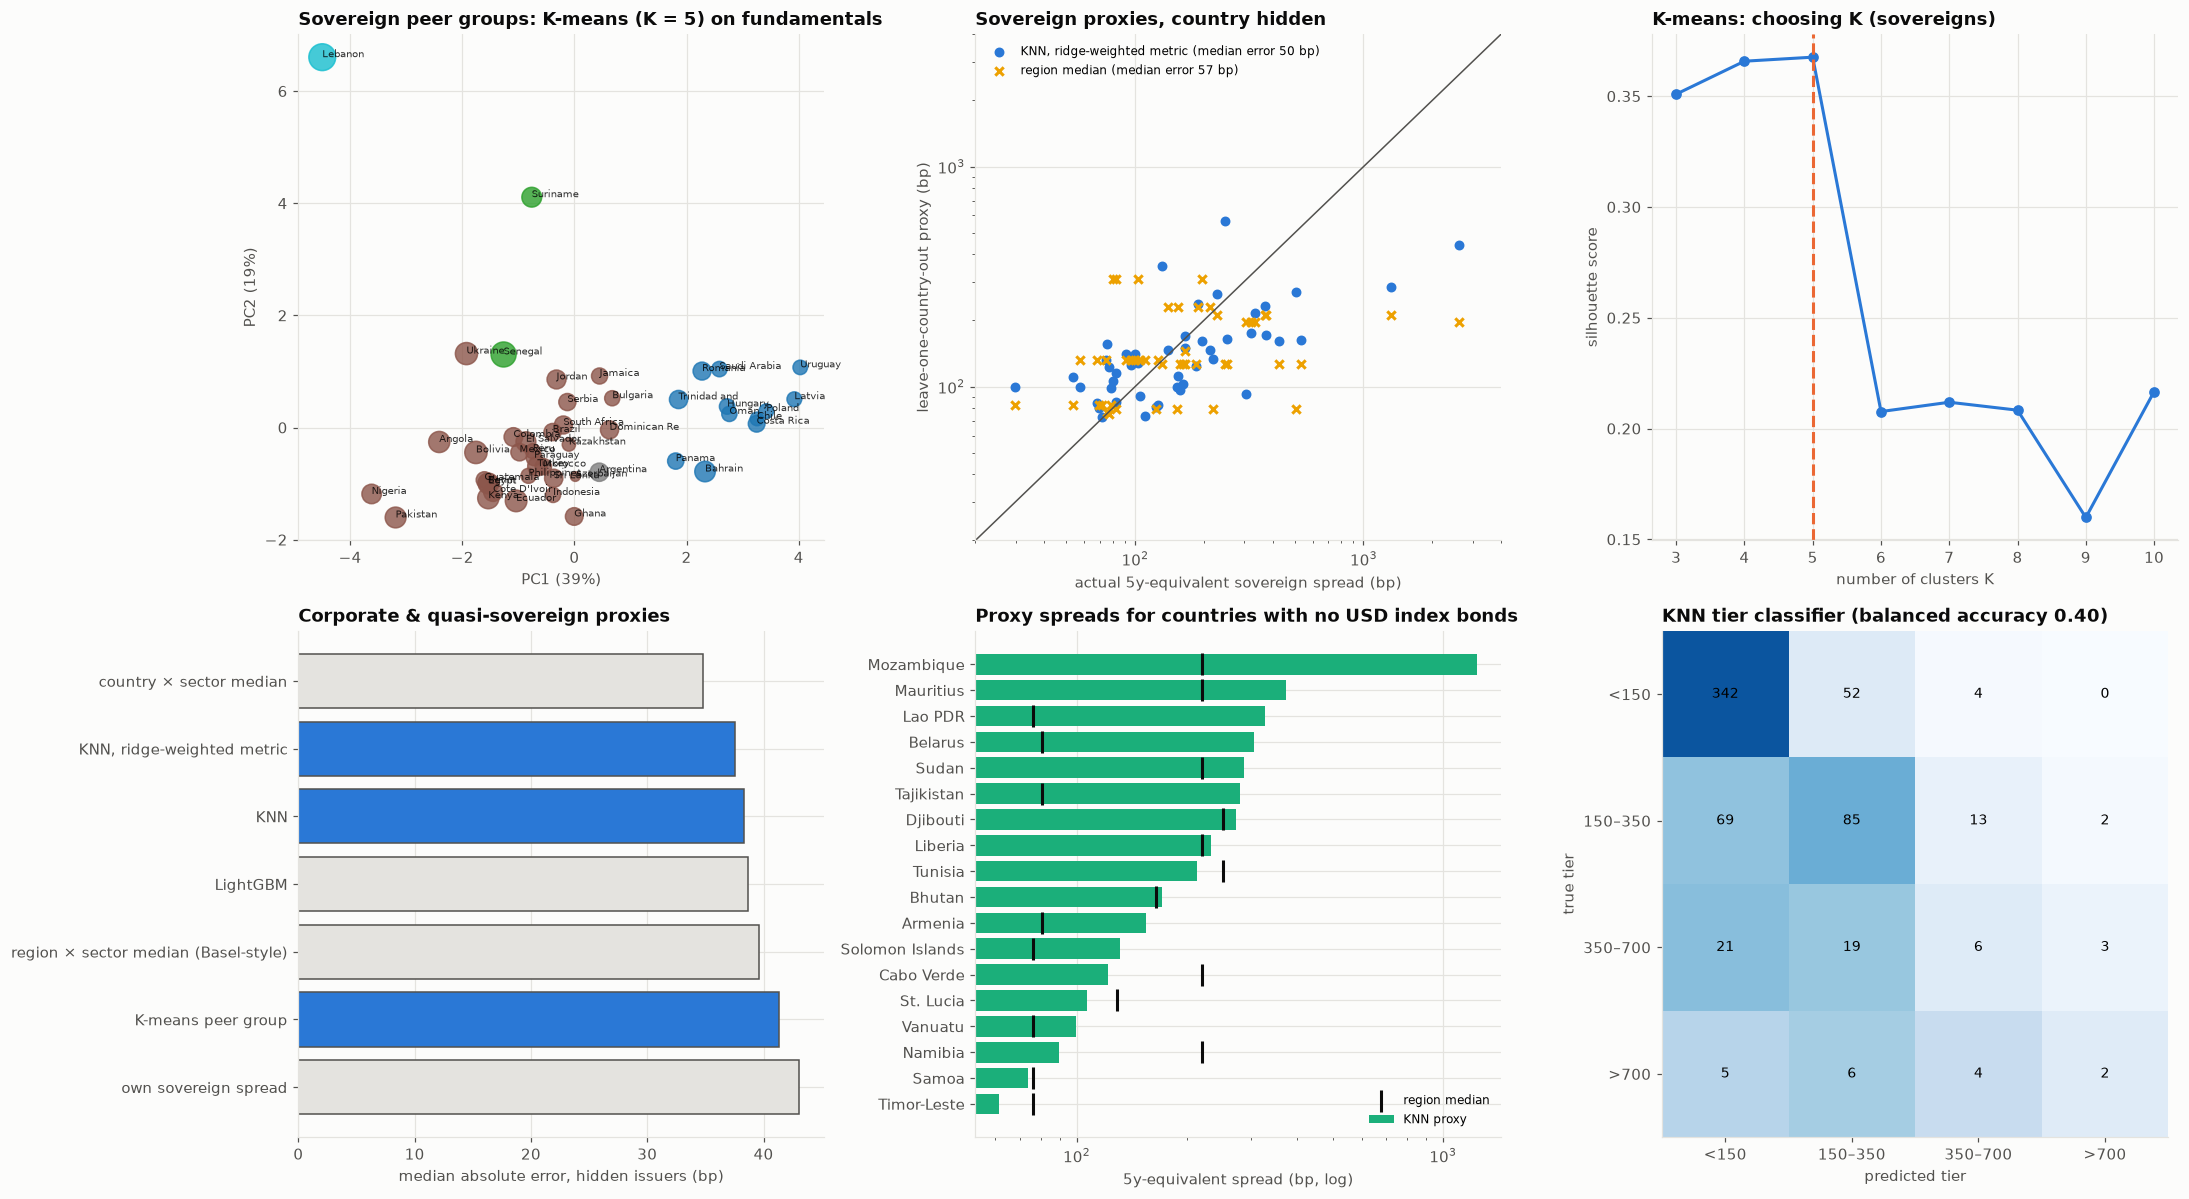

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
ax = axes[0, 0]
pca = PCA(2).fit(Z)
P = pca.transform(Z)
sc_ = ax.scatter(
    P[:, 0],
    P[:, 1],
    c=sov["cluster"],
    cmap="tab10",
    s=40 + 60 * (np.log(sov["s5"]) - np.log(sov["s5"]).min()),
    alpha=0.8,
)
for (x_, y_), n_ in zip(P, sov["country"]):
    ax.annotate(n_[:12], (x_, y_), fontsize=6.5, alpha=0.8)
ax.set_title(f"Sovereign peer groups: K-means (K = {K_SOV}) on fundamentals")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax = axes[0, 1]
lim = (20, 4000)
for m_, c, mk in [
    ("KNN, ridge-weighted metric", PALETTE[0], "o"),
    ("region median", PALETTE[3], "x"),
]:
    ax.scatter(
        sov["s5"],
        sov[f"proxy_{m_}"],
        color=c,
        marker=mk,
        s=30,
        label=(
            f"{m_} (median error"
            f" {sov_score.loc[m_, 'median abs error (bp)']:.0f} bp)"
        ),
    )
ax.plot(lim, lim, color=INK_2, lw=1)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("actual 5y-equivalent sovereign spread (bp)")
ax.set_ylabel("leave-one-country-out proxy (bp)")
ax.set_title("Sovereign proxies, country hidden")
ax.legend(fontsize=8)
ax = axes[0, 2]
ax.plot(list(sil), list(sil.values()), "o-", color=PALETTE[0])
ax.axvline(K_SOV, color=PALETTE[1], ls="--")
ax.set_xlabel("number of clusters K")
ax.set_ylabel("silhouette score")
ax.set_title("K-means: choosing K (sovereigns)")
ax = axes[1, 0]
cs = corp_score["median abs error (bp)"].sort_values()
ax.barh(
    cs.index,
    cs.values,
    color=[
        PALETTE[0] if ("KNN" in i or "K-means" in i) else GRID
        for i in cs.index
    ],
    edgecolor=INK_2,
)
ax.invert_yaxis()
ax.set_xlabel("median absolute error, hidden issuers (bp)")
ax.set_title("Corporate & quasi-sovereign proxies")
ax = axes[1, 1]
show = unq.sort_values("proxy_bp").iloc[
    np.linspace(0, len(unq) - 1, min(18, len(unq))).astype(int)
]
ax.barh(
    show["wb_name"].str[:22],
    show["proxy_bp"],
    color=PALETTE[2],
    label="KNN proxy",
)
ax.scatter(
    show["region median bp"],
    show["wb_name"].str[:22],
    color=INK,
    marker="|",
    s=200,
    label="region median",
)
ax.set_xscale("log")
ax.set_xlabel("5y-equivalent spread (bp, log)")
ax.set_title("Proxy spreads for countries with no USD index bonds")
ax.legend(fontsize=8)
ax = axes[1, 2]
im = ax.imshow(
    cmat.to_numpy() / cmat.to_numpy().sum(1, keepdims=True),
    cmap="Blues",
    vmin=0,
    vmax=1,
)
ax.set_xticks(range(4))
ax.set_xticklabels(TIER_NAMES)
ax.set_yticks(range(4))
ax.set_yticklabels(TIER_NAMES)
for i in range(4):
    for j in range(4):
        ax.text(
            j, i, int(cmat.iat[i, j]), ha="center", va="center", fontsize=9
        )
ax.set_xlabel("predicted tier")
ax.set_ylabel("true tier")
ax.set_title(
    "KNN tier classifier (balanced accuracy"
    f" {tier_score['KNN classifier']:.2f})"
)
ax.grid(False)
plt.tight_layout()
save_fig(fig, "01_peer_groups_proxies_tiers")
plt.show()

## 9. Reading the results and limitations

**The data.** The data are 1,722 USD bonds of 727 issuers in 75 locations. Spreads rise about 15% per doubling of maturity, and that pooled slope puts every issuer on a 5-year-equivalent basis.

**Sovereigns: fundamentals beat geography.** Leave-one-country-out over 47 sovereigns:

| Method | Median absolute error | Rank correlation |
|---|---|---|
| Ridge | **38 bp** | 0.76 |
| LightGBM | 40 bp | — |
| Plain KNN | 47 bp | — |
| KNN with learned metric | 50 bp | 0.68 |
| K-means cluster median | 54 bp | — |
| Region median (the bucket proxy) | 57 bp | 0.28 |

- **Every method that uses fundamentals beats the region bucket**, above all in ranking: the region median barely orders countries correctly.
- **Learned metric.** The ridge-learned metric shows what similarity should mean for sovereign credit: external debt counts almost three times as much as an average feature, followed by reserves, political stability and income. Neighbours chosen that way rank countries better (0.68 vs 0.61) without lowering the median error, a reminder that 47 observations leave little room for fancier learners.

**K-means peer groups** have a silhouette of only 0.37. They mostly separate a strong group (Gulf, Central Europe, Chile, Panama, Uruguay: median 83 bp) from mainstream emerging markets (31 countries, 158 bp) and isolate the outliers (Senegal and Suriname, about 780 bp; Lebanon, in default since 2020, 2,600 bp). They are useful as a description, but too coarse for pricing.

**Corporates and quasi-sovereigns: the country is most of the answer.**
- **Same-country peers win.** For 633 non-sovereign issuers hidden in turn, the best proxy is the median of quoted peers in the **same country and sector** (35 bp median error).
- **No same-country peers.** KNN (38 bp, plain or with the learned metric), LightGBM (39 bp), the Basel-style region × sector bucket (40 bp) and K-means peer groups (41 bp) are within a few basis points of each other. The issuer's own sovereign spread plus a typical premium is worst (45 bp).

**What the ML adds** is less a smaller median error than a smaller **bias in the tail and a traceable peer list**. Where a counterparty's country has quoted names, use them. Where it does not (46% of these issuers sit in countries without quoted sovereign bonds), KNN on the sovereign proxy and fundamentals is a defensible, auditable replacement for a regional bucket.

**Tiers are hard.** The KNN classifier assigns hidden issuers to the right 5-year spread tier with a balanced accuracy of **0.40**: 0.42 when KNN regression is cut into tiers, 0.40 for the bucket, 0.25 for always guessing the most common tier. Distressed names (> 700 bp) are almost never recognised from fundamentals: 2 of 17. Distress is driven by events (restructurings, sanctions, fraud) that macro data do not see.

**CVA impact.** With the actual spreads, the median CVA of a $100mm 5-year swap is about $43,000, and the 633-counterparty portfolio carries $39.6mm. The region × sector bucket **understates portfolio CVA by 19%** because it averages away the high-spread names. The KNN proxy understates it by 7%, and its per-counterparty error is slightly smaller ($13,300 vs $14,300 median).

**Unquoted countries.** The engine gives a proxy and three named peers for 79 low- and middle-income countries without USD index bonds, for example:

| Country | Proxy | Nearest quoted peers |
|---|---|---|
| Viet Nam | 72 bp | Ghana, Indonesia, Azerbaijan |
| India | 82 bp | Philippines, Indonesia, Morocco |
| China | 91 bp | — |
| Bangladesh | 231 bp | — |
| Ethiopia | 343 bp | — |
| Zimbabwe | 388 bp | — |
| Mozambique | 1,240 bp | Lebanon, Senegal, Suriname |

These are where a validator must step in. Ethiopia has been in default on its Eurobond since December 2023 and Zimbabwe is in arrears, yet their fundamentals place them among ordinary frontier credits. Libya (86 bp) looks like an oil exporter, not a conflict state. A proxy built on fundamentals needs an overlay for default status, sanctions and conflict.

**Limitations**
- **One snapshot.** The holdings date fixes the proxies, so nothing here tests stability over time. A production proxy needs history and a re-mapping policy.
- **No ratings.** Ratings would sharpen every method. The point here is to show what works when they are absent.
- **Proxy spread definition.** Spreads are Treasury z-spreads of USD bonds, not CDS. Quasi-sovereign and corporate bonds in the indices are larger and more liquid than the typical unquoted counterparty, so proxies are biased towards tighter spreads.
- **Stale and imputed fundamentals.** World Bank data lag one to two years. External debt is imputed for high-income countries (flagged), and governance indicators are slow-moving.
- **K-means sees only the snapshot.** Silhouette keeps rising up to 28–30 corporate clusters, a sign that the data have no natural grouping beyond country and sector. The chosen K is the upper end of the range searched.
- **Stylised CVA.** The exposure profile and flat hazard are illustrations of the proxy effect, not a CVA engine.

In [12]:
sov.drop(columns=FX).to_csv(
    OUT_DIR / "sovereign_proxies_loco.csv", index=False
)
sov_score.to_csv(OUT_DIR / "sovereign_proxy_scores.csv")
prof.to_csv(OUT_DIR / "sovereign_peer_groups.csv")
corp_score.to_csv(OUT_DIR / "corporate_proxy_scores.csv")
tier_score.to_csv(OUT_DIR / "tier_classifier_scores.csv")
unq.to_csv(OUT_DIR / "unquoted_country_proxies.csv", index=False)
cva_tab.to_csv(OUT_DIR / "cva_proxy_impact.csv")
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_peer_groups_proxies_tiers.png, corporate_proxy_scores.csv, cva_proxy_impact.csv, sovereign_peer_groups.csv, sovereign_proxies_loco.csv, sovereign_proxy_scores.csv, tier_classifier_scores.csv, unquoted_country_proxies.csv


## References

### Finance and regulation

- Basel Committee on Banking Supervision. (2020). *Targeted revisions to the credit valuation adjustment risk framework*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d507.htm
- International Accounting Standards Board. (2011). *IFRS 13 Fair value measurement*. IFRS Foundation. https://www.ifrs.org/issued-standards/list-of-standards/ifrs-13-fair-value-measurement/
- Cantor, R., & Packer, F. (1996). Determinants and impact of sovereign credit ratings. *Economic Policy Review, 2*(2), 37–53. https://doi.org/10.2139/ssrn.1028774
- Longstaff, F. A., Pan, J., Pedersen, L. H., & Singleton, K. J. (2011). How sovereign is sovereign credit risk? *American Economic Journal: Macroeconomics, 3*(2), 75–103. https://doi.org/10.1257/mac.3.2.75
- Kaufmann, D., Kraay, A., & Mastruzzi, M. (2011). The Worldwide Governance Indicators: Methodology and analytical issues. *Hague Journal on the Rule of Law, 3*(2), 220–246. https://doi.org/10.1017/S1876404511200046

### Machine learning and deep learning

- Lloyd, S. (1982). Least squares quantization in PCM. *IEEE Transactions on Information Theory, 28*(2), 129–137. https://doi.org/10.1109/TIT.1982.1056489
- Cover, T., & Hart, P. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory, 13*(1), 21–27. https://doi.org/10.1109/TIT.1967.1053964
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7
- Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55–67. https://doi.org/10.1080/00401706.1970.10488634